# LGBTQ+ Tweet Categorization - Zero-Shot Classification



## Overview

This notebook classifies LGBTQ+-labeled corporate tweets into four meaningful categories defined by the research team:

| Category | Description | Example |
|----------|-------------|--------|
| **Support** | General expressions of solidarity, inclusivity, or celebration | "We're proud to celebrate Pride Month with our LGBTQ+ community" |
| **Company Action** | Specific policies, programs, donations, or initiatives taken by the company | "We've launched a new benefits package covering same-sex partners" |
| **Employee / Executive Profile** | Spotlights on individual employees or executives discussing pride or identity | "Meet Maria, an openly gay engineer who leads our DEI council" |
| **Political Statement** | References to legislation, rights, or political positions | "We oppose legislation that discriminates against LGBTQ+ individuals" |

### Why Zero-Shot Classification?

Topic modeling (like LDA) finds themes automatically but doesn't know which categories we want in advance, we'd have to guess what the output means. Zero-shot classification works the other way: we tell it our four categories and it scores each tweet against them directly. This is better suited to this task because the categories are already defined by the research goals.

The model used is `facebook/bart-large-mnli` — a pre-trained model that understands natural language and does not require any training data from our dataset.



---
## Section 1 — Setup

### 1.1 — Install & Import Libraries

In [7]:
# ── Install Hugging Face transformers (includes zero-shot pipeline) ───────────
!pip install transformers torch --quiet

In [8]:
# ── Core libraries ───────────────────────────────────────────────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from IPython.display import display
import warnings
import time
import os
warnings.filterwarnings('ignore')

# ── Hugging Face zero-shot pipeline ─────────────────────────────────────────
from transformers import pipeline

# ── Plot styling (matches main notebook) ────────────────────────────────────
sns.set_theme(style='whitegrid', context='notebook', font_scale=1.15)
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.titlesize': 14,
    'axes.titleweight': 'bold',
    'axes.labelsize': 12,
    'figure.titlesize': 16,
    'figure.titleweight': 'bold',
})

# ── Colors ───────────────────────────────────────────────────────────────────
LGBTQ_COLOR     = '#8B5CF6'   # purple
NON_LGBTQ_COLOR = '#64748B'   # slate gray
ACCENT_COLOR    = '#F59E0B'   # amber

# One color per category
CAT_COLORS = {
    'Support'             : '#22C55E',   # green
    'Company Action'      : '#3B82F6',   # blue
    'Employee Profile'    : '#F59E0B',   # amber
    'Political Statement' : '#EF4444',   # red
}

print('✅ Libraries imported successfully.')

✅ Libraries imported successfully.


### 1.2 — Load Dataset



In [9]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [6]:
FILE_PATH = '/content/drive/MyDrive/Colab Notebooks/Tweets.csv'

df = pd.read_csv(FILE_PATH, low_memory=False, on_bad_lines='skip')
# ── Parse dates ──────────────────────────────────────────────────────────────
df['createdAt'] = pd.to_datetime(df['createdAt'], utc=True, errors='coerce')
df['year']      = df['createdAt'].dt.year
df['month']     = df['createdAt'].dt.month

print(f'✅ Dataset loaded: {df.shape[0]:,} rows × {df.shape[1]} columns')
print(f'   LGBTQ+ tweets : {(df["binary"] == 1).sum():,}')

✅ Dataset loaded: 1,585,500 rows × 19 columns
   LGBTQ+ tweets : 52,791


### 1.3 — Filter to LGBTQ+ Tweets

Classification only runs on the LGBTQ+-labeled subset. This keeps it focused and manageable.

In [10]:
# ── Isolate LGBTQ+ tweets ────────────────────────────────────────────────────
df_lgbtq = df[df['binary'] == 1].copy().reset_index(drop=True)

# Clean text — remove nulls
df_lgbtq['text'] = df_lgbtq['text'].fillna('').astype(str)

print(f'✅ LGBTQ+ subset: {len(df_lgbtq):,} tweets')
print(f'   Companies : {df_lgbtq["author_userName"].nunique():,}')
print(f'   Date range: {df_lgbtq["createdAt"].min().date()}  →  {df_lgbtq["createdAt"].max().date()}')

✅ LGBTQ+ subset: 52,791 tweets
   Companies : 390
   Date range: 2018-01-01  →  2024-07-14


---
## Section 2 — Define Categories & Load Model

### 2.1 — Category Definitions

The labels below are what the model scores each tweet against. The wording matters — clear, descriptive labels produce better results than single words.

In [11]:
# ── Four research categories ──────────────────────────────────────────────────
# These are passed directly to the zero-shot classifier as candidate labels.
# Changes to wording can be done here if needed
CANDIDATE_LABELS = [
    'support and celebration of LGBTQ+ community and Pride',
    'specific company action, policy, program, or initiative for LGBTQ+ inclusion',
    'employee or executive profile or personal story about LGBTQ+ identity',
    'political statement or position on LGBTQ+ legislation or rights',
]

# Shorter display names mapped to those labels (used in charts and tables)
LABEL_MAP = {
    'support and celebration of LGBTQ+ community and Pride'                         : 'Support',
    'specific company action, policy, program, or initiative for LGBTQ+ inclusion'  : 'Company Action',
    'employee or executive profile or personal story about LGBTQ+ identity'          : 'Employee Profile',
    'political statement or position on LGBTQ+ legislation or rights'                : 'Political Statement',
}

print('Categories defined:')
for short, full in zip(LABEL_MAP.values(), LABEL_MAP.keys()):
    print(f'  [{short}]  →  "{full}"')

Categories defined:
  [Support]  →  "support and celebration of LGBTQ+ community and Pride"
  [Company Action]  →  "specific company action, policy, program, or initiative for LGBTQ+ inclusion"
  [Employee Profile]  →  "employee or executive profile or personal story about LGBTQ+ identity"
  [Political Statement]  →  "political statement or position on LGBTQ+ legislation or rights"


### 2.2 — Load Zero-Shot Classifier

This downloads the `facebook/bart-large-mnli` model

In [12]:
# ── Load the zero-shot classification pipeline ───────────────────────────────
# device=0 uses the GPU (much faster); device=-1 uses CPU (slower but works)
print('Loading model... (downloads ~1.6 GB on first run, then cached)')

classifier = pipeline(
    'zero-shot-classification',
    model='facebook/bart-large-mnli',
    device=0   # GPU — change to -1 if you did not enable GPU runtime
)

print('✅ Model loaded and ready.')

Loading model... (downloads ~1.6 GB on first run, then cached)


config.json:   0%|          | 0.00/1.15k [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.63G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

✅ Model loaded and ready.


### 2.3 — Quick Test on 5 Tweets

Testing the classifier on a small sample before running the full dataset.

In [13]:
# ── Test on 5 sample tweets ──────────────────────────────────────────────────
test_tweets = df_lgbtq['text'].sample(5, random_state=42).tolist()

print('CLASSIFIER TEST — 5 SAMPLE TWEETS')
print('═' * 60)

for tweet in test_tweets:
    result = classifier(tweet[:512], CANDIDATE_LABELS)
    top_label = LABEL_MAP[result['labels'][0]]
    top_score = result['scores'][0]
    print(f'\nTweet   : "{tweet[:120]}"')
    print(f'Category: {top_label}  (confidence: {top_score:.3f})')
    print()

print('═' * 60)
print('\n✅ Test complete. Review results above before running full classification.')
print('   If any labels look wrong, adjust the CANDIDATE_LABELS wording in Section 2.1.')

---
## Section 3 — Run Full Classification

This is the main processing step. It runs the classifier on all ~52,000 LGBTQ+ tweets in batches.



In [14]:
CHECKPOINT_PATH = '/content/drive/MyDrive/lgbtq_classified_checkpoint.csv'
BATCH_SIZE      = 32    # tweets per batch — GPU handles this comfortably
SAVE_EVERY      = 1000  # save checkpoint every N tweets

# ── Resume from checkpoint if one exists ────────────────────────────────────
if os.path.exists(CHECKPOINT_PATH):
    df_done = pd.read_csv(CHECKPOINT_PATH)
    done_indices = set(df_done['original_index'].tolist())
    print(f'✅ Checkpoint found: {len(df_done):,} tweets already classified. Resuming...')
else:
    df_done = pd.DataFrame()
    done_indices = set()
    print('No checkpoint found. Starting from scratch.')

# ── Identify remaining tweets ────────────────────────────────────────────────
remaining = df_lgbtq[~df_lgbtq.index.isin(done_indices)].copy()
print(f'Tweets remaining to classify: {len(remaining):,}')
print(f'Estimated time (GPU): ~{len(remaining)//60//60}h {(len(remaining)//60)%60}m')

# ── Run classification in batches ────────────────────────────────────────────
results = []
texts   = remaining['text'].tolist()
indices = remaining.index.tolist()

start_time = time.time()

for i in range(0, len(texts), BATCH_SIZE):
    batch_texts   = [t[:512] for t in texts[i:i+BATCH_SIZE]]   # truncate to model max
    batch_indices = indices[i:i+BATCH_SIZE]

    batch_results = classifier(batch_texts, CANDIDATE_LABELS, batch_size=BATCH_SIZE)

    for idx, res in zip(batch_indices, batch_results):
        top_label = LABEL_MAP[res['labels'][0]]
        top_score = res['scores'][0]
        all_scores = {LABEL_MAP[l]: s for l, s in zip(res['labels'], res['scores'])}
        results.append({
            'original_index'        : idx,
            'category'              : top_label,
            'confidence'            : round(top_score, 4),
            'score_support'         : round(all_scores.get('Support', 0), 4),
            'score_company_action'  : round(all_scores.get('Company Action', 0), 4),
            'score_employee_profile': round(all_scores.get('Employee Profile', 0), 4),
            'score_political'       : round(all_scores.get('Political Statement', 0), 4),
        })

    # ── Progress update and checkpoint ───────────────────────────────────────
    processed = len(results)
    if processed % SAVE_EVERY < BATCH_SIZE or i + BATCH_SIZE >= len(texts):
        elapsed  = time.time() - start_time
        rate     = processed / elapsed if elapsed > 0 else 1
        remaining_t = (len(texts) - processed) / rate
        print(f'  [{processed:>6,} / {len(texts):,}]  '
              f'Speed: {rate:.0f} tweets/sec  '
              f'ETA: {remaining_t/60:.0f} min')

        # Save checkpoint
        batch_df = pd.DataFrame(results)
        combined = pd.concat([df_done, batch_df], ignore_index=True) if len(df_done) > 0 else batch_df
        combined.to_csv(CHECKPOINT_PATH, index=False)

print(f'\n✅ Classification complete!')

No checkpoint found. Starting from scratch.
Tweets remaining to classify: 52,791
Estimated time (GPU): ~14h 39m


[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


  [ 1,024 / 52,791]  Speed: 11 tweets/sec  ETA: 82 min
  [ 2,016 / 52,791]  Speed: 10 tweets/sec  ETA: 82 min
  [ 3,008 / 52,791]  Speed: 11 tweets/sec  ETA: 76 min
  [ 4,000 / 52,791]  Speed: 11 tweets/sec  ETA: 73 min
  [ 5,024 / 52,791]  Speed: 11 tweets/sec  ETA: 73 min
  [ 6,016 / 52,791]  Speed: 11 tweets/sec  ETA: 70 min
  [ 7,008 / 52,791]  Speed: 11 tweets/sec  ETA: 70 min
  [ 8,000 / 52,791]  Speed: 11 tweets/sec  ETA: 70 min
  [ 9,024 / 52,791]  Speed: 11 tweets/sec  ETA: 69 min
  [10,016 / 52,791]  Speed: 11 tweets/sec  ETA: 67 min
  [11,008 / 52,791]  Speed: 11 tweets/sec  ETA: 65 min
  [12,000 / 52,791]  Speed: 11 tweets/sec  ETA: 64 min
  [13,024 / 52,791]  Speed: 11 tweets/sec  ETA: 63 min
  [14,016 / 52,791]  Speed: 10 tweets/sec  ETA: 62 min
  [15,008 / 52,791]  Speed: 10 tweets/sec  ETA: 60 min
  [16,000 / 52,791]  Speed: 10 tweets/sec  ETA: 59 min
  [17,024 / 52,791]  Speed: 10 tweets/sec  ETA: 57 min
  [18,016 / 52,791]  Speed: 10 tweets/sec  ETA: 56 min
  [19,008 

In [15]:
# ── Merge classification results back onto the LGBTQ+ dataframe ─────────────
classified = pd.read_csv(CHECKPOINT_PATH)
classified = classified.set_index('original_index')

df_lgbtq = df_lgbtq.join(classified, how='left')

# ── Save final merged file ───────────────────────────────────────────────────
df_lgbtq.to_csv('/content/drive/MyDrive/lgbtq_tweets_classified.csv', index=False)

print(f'✅ Results merged. Classified: {df_lgbtq["category"].notna().sum():,} tweets')
print(f'   Saved to: lgbtq_tweets_classified.csv')
print(f'\nCategory distribution:')
print(df_lgbtq['category'].value_counts().to_string())

✅ Results merged. Classified: 52,791 tweets
   Saved to: lgbtq_tweets_classified.csv

Category distribution:
category
Employee Profile       37018
Company Action          7969
Support                 5471
Political Statement     2333


---
## Section 4 — Overall Category Distribution

How are LGBTQ+ corporate tweets distributed across the four categories?

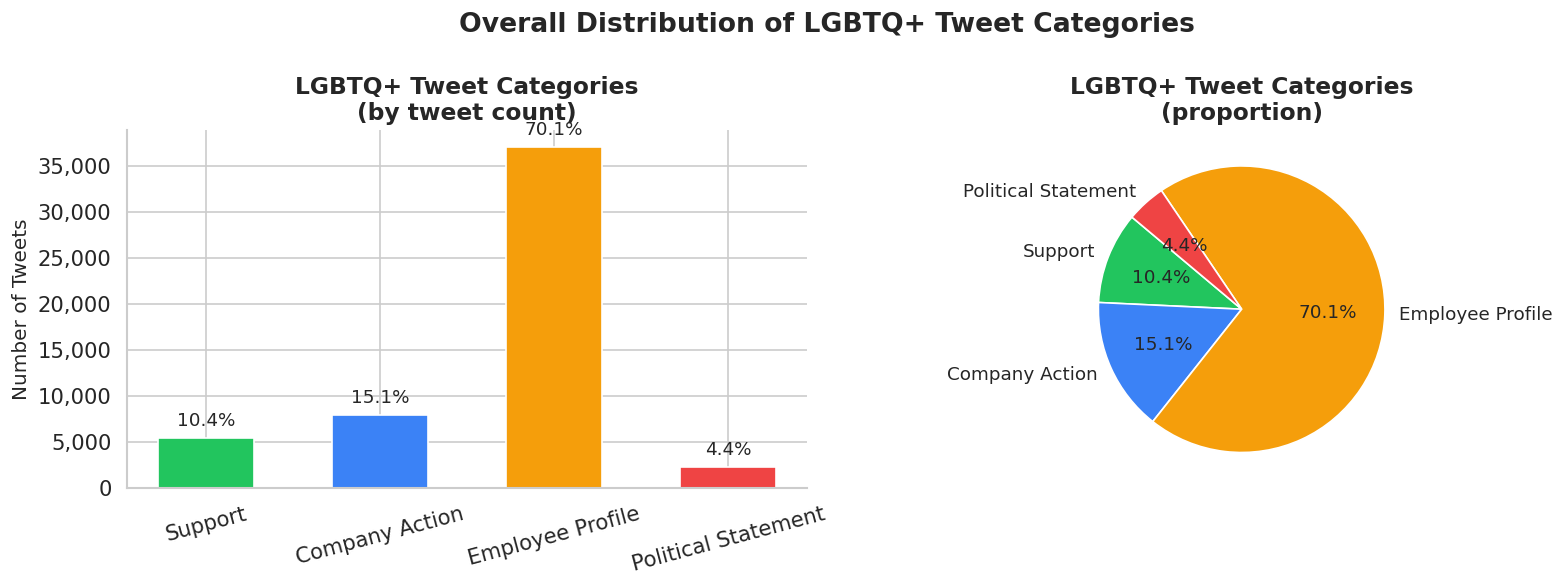

Category,Count,Percentage
Support,"5,471",10.4%
Company Action,"7,969",15.1%
Employee Profile,"37,018",70.1%
Political Statement,"2,333",4.4%


In [16]:
cat_order  = ['Support', 'Company Action', 'Employee Profile', 'Political Statement']
cat_colors = [CAT_COLORS[c] for c in cat_order]

cat_counts = df_lgbtq['category'].value_counts().reindex(cat_order).fillna(0)
cat_pcts   = (cat_counts / cat_counts.sum() * 100).round(1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ── Bar chart ────────────────────────────────────────────────────────────────
bars = axes[0].bar(cat_order, cat_counts, color=cat_colors, edgecolor='white', width=0.55)
axes[0].bar_label(bars, labels=[f'{p:.1f}%' for p in cat_pcts], padding=5, fontsize=11)
axes[0].set_title('LGBTQ+ Tweet Categories\n(by tweet count)')
axes[0].set_ylabel('Number of Tweets')
axes[0].tick_params(axis='x', rotation=15)
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
sns.despine(ax=axes[0])

# ── Pie chart ────────────────────────────────────────────────────────────────
axes[1].pie(
    cat_counts,
    labels=cat_order,
    colors=cat_colors,
    autopct='%1.1f%%',
    startangle=140,
    textprops={'fontsize': 11}
)
axes[1].set_title('LGBTQ+ Tweet Categories\n(proportion)')

fig.suptitle('Overall Distribution of LGBTQ+ Tweet Categories')
plt.tight_layout()
plt.savefig('fig_cat_overall_dist.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Summary table ────────────────────────────────────────────────────────────
summary = pd.DataFrame({'Category': cat_order,
                         'Count': cat_counts.values,
                         'Percentage': cat_pcts.values})
display(summary.style.format({'Count': '{:,}', 'Percentage': '{:.1f}%'}).hide(axis='index'))

---
## Section 5 — Category Trends Over Time

Has the mix of categories shifted from 2018 to 2023? This reveals whether corporate LGBTQ+ communication has become more or less action-oriented or politically engaged over time.

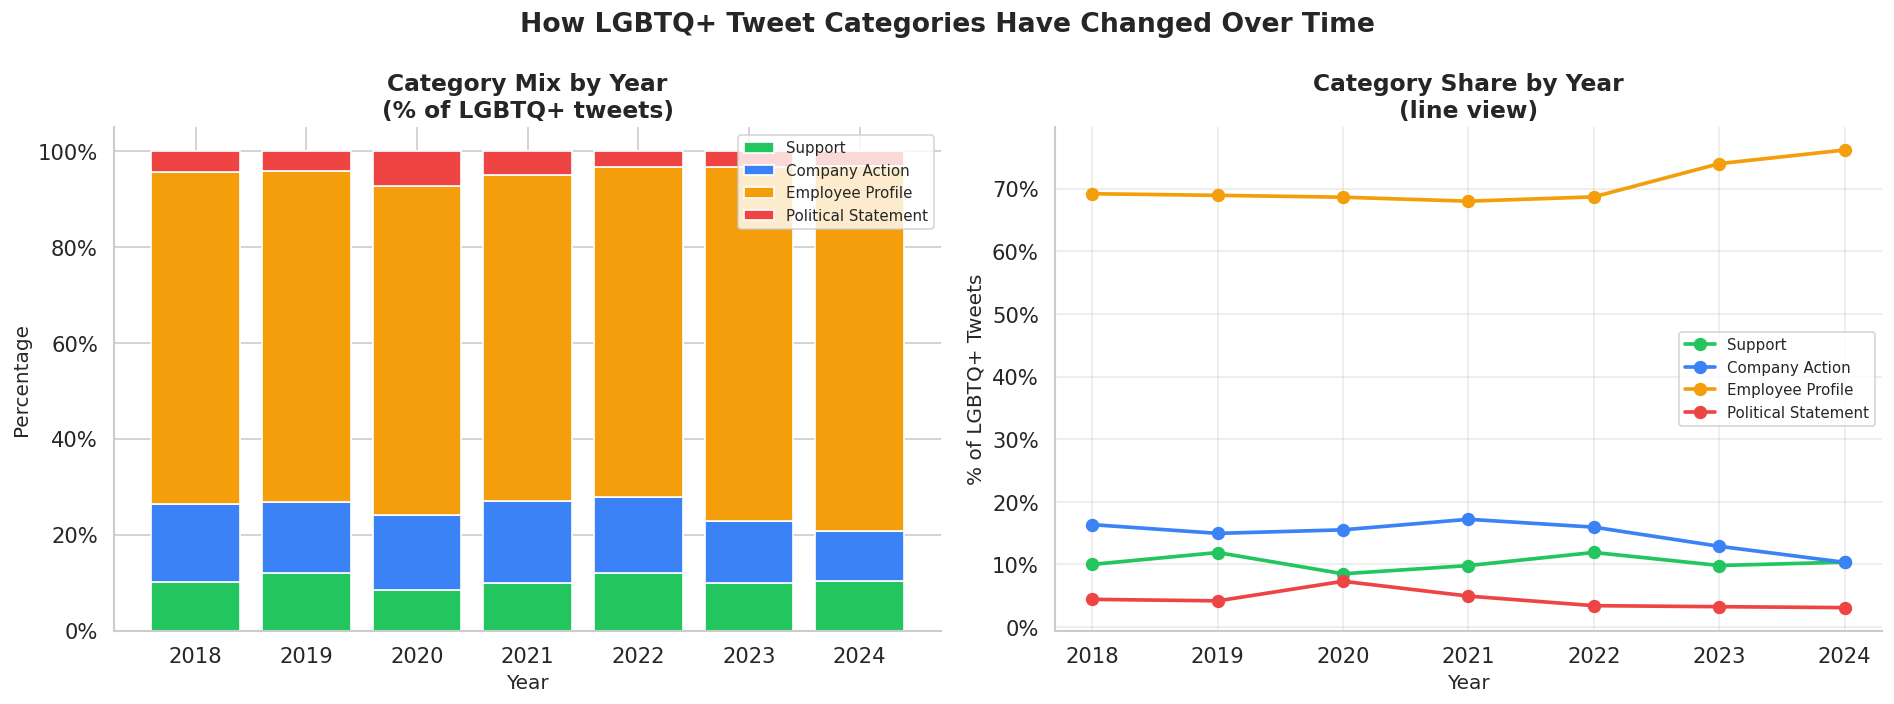

In [17]:
# ── Category counts and % by year ────────────────────────────────────────────
yearly_cats = (
    df_lgbtq.groupby(['year', 'category'])
    .size()
    .reset_index(name='count')
)

yearly_pivot     = yearly_cats.pivot(index='year', columns='category', values='count').fillna(0)
yearly_pivot_pct = yearly_pivot.div(yearly_pivot.sum(axis=1), axis=0) * 100

# ── Stacked bar chart (%) ────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Percentage stacked bars
bottom = np.zeros(len(yearly_pivot_pct))
for cat in cat_order:
    if cat in yearly_pivot_pct.columns:
        vals = yearly_pivot_pct[cat].values
        axes[0].bar(yearly_pivot_pct.index, vals, bottom=bottom,
                    label=cat, color=CAT_COLORS[cat], edgecolor='white')
        bottom += vals

axes[0].set_title('Category Mix by Year\n(% of LGBTQ+ tweets)')
axes[0].set_xlabel('Year')
axes[0].set_ylabel('Percentage')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:.0f}%'))
axes[0].legend(loc='upper right', fontsize=9)
axes[0].set_xticks(yearly_pivot_pct.index)
sns.despine(ax=axes[0])

# Line chart — each category over time
for cat in cat_order:
    if cat in yearly_pivot_pct.columns:
        axes[1].plot(
            yearly_pivot_pct.index,
            yearly_pivot_pct[cat],
            marker='o', linewidth=2.2,
            color=CAT_COLORS[cat],
            label=cat, markersize=7
        )

axes[1].set_title('Category Share by Year\n(line view)')
axes[1].set_xlabel('Year')
axes[1].set_ylabel('% of LGBTQ+ Tweets')
axes[1].legend(fontsize=9)
axes[1].set_xticks(yearly_pivot_pct.index)
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:.0f}%'))
axes[1].grid(True, alpha=0.4)
sns.despine(ax=axes[1])

fig.suptitle('How LGBTQ+ Tweet Categories Have Changed Over Time')
plt.tight_layout()
plt.savefig('fig_cat_yearly_trend.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Section 6 — Category by Month (Seasonality)

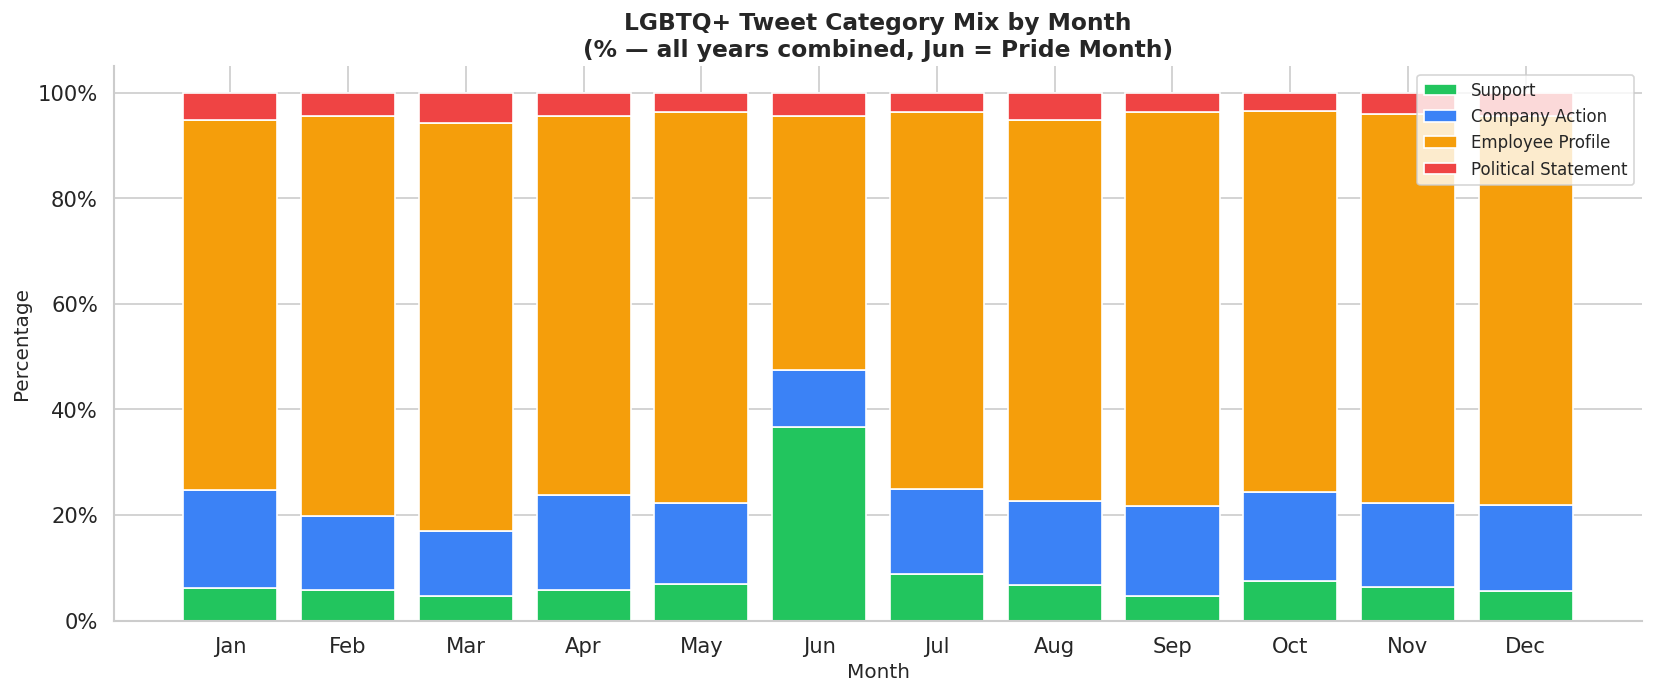

In [18]:
month_names = ['Jan','Feb','Mar','Apr','May','Jun',
               'Jul','Aug','Sep','Oct','Nov','Dec']

monthly_cats = (
    df_lgbtq.groupby(['month', 'category'])
    .size()
    .reset_index(name='count')
)
monthly_pivot     = monthly_cats.pivot(index='month', columns='category', values='count').fillna(0)
monthly_pivot_pct = monthly_pivot.div(monthly_pivot.sum(axis=1), axis=0) * 100
monthly_pivot_pct.index = [month_names[m-1] for m in monthly_pivot_pct.index]

fig, ax = plt.subplots(figsize=(14, 6))

bottom = np.zeros(len(monthly_pivot_pct))
for cat in cat_order:
    if cat in monthly_pivot_pct.columns:
        vals = monthly_pivot_pct[cat].values
        ax.bar(monthly_pivot_pct.index, vals, bottom=bottom,
               label=cat, color=CAT_COLORS[cat], edgecolor='white')
        bottom += vals

ax.set_title('LGBTQ+ Tweet Category Mix by Month\n(% — all years combined, Jun = Pride Month)')
ax.set_xlabel('Month')
ax.set_ylabel('Percentage')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:.0f}%'))
ax.legend(loc='upper right', fontsize=10)
sns.despine()
plt.tight_layout()
plt.savefig('fig_cat_monthly.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Section 7 — Category by Company

Which companies focus on which types of LGBTQ+ communication?

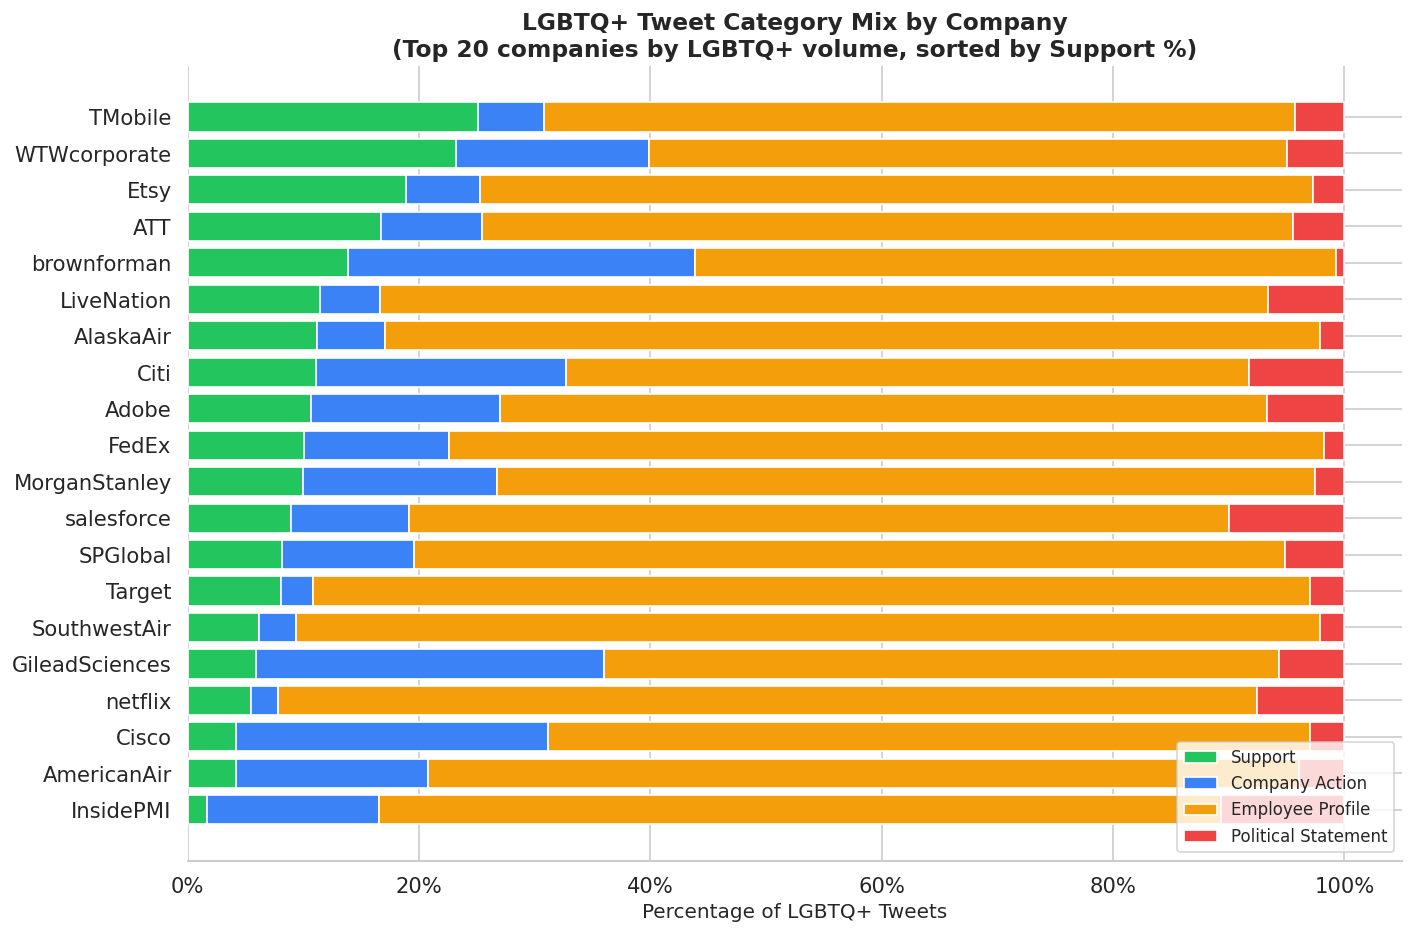

In [19]:
# ── Category breakdown per company (top 20 by LGBTQ+ volume) ─────────────────
top20_companies = (
    df_lgbtq['author_userName']
    .value_counts()
    .head(20)
    .index.tolist()
)

company_cats = (
    df_lgbtq[df_lgbtq['author_userName'].isin(top20_companies)]
    .groupby(['author_userName', 'category'])
    .size()
    .reset_index(name='count')
)

company_pivot     = company_cats.pivot(index='author_userName', columns='category', values='count').fillna(0)
company_pivot_pct = company_pivot.div(company_pivot.sum(axis=1), axis=0) * 100

# Sort by Support % so most supportive companies are at top
company_pivot_pct = company_pivot_pct.sort_values('Support', ascending=True)

fig, ax = plt.subplots(figsize=(12, 8))

left = np.zeros(len(company_pivot_pct))
for cat in cat_order:
    if cat in company_pivot_pct.columns:
        vals = company_pivot_pct[cat].values
        ax.barh(company_pivot_pct.index, vals, left=left,
                label=cat, color=CAT_COLORS[cat], edgecolor='white')
        left += vals

ax.set_title('LGBTQ+ Tweet Category Mix by Company\n(Top 20 companies by LGBTQ+ volume, sorted by Support %)')
ax.set_xlabel('Percentage of LGBTQ+ Tweets')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:.0f}%'))
ax.legend(loc='lower right', fontsize=10)
sns.despine(left=True)
plt.tight_layout()
plt.savefig('fig_cat_by_company.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Section 8 — Confidence Score Analysis

The classifier assigns a confidence score to each tweet. Low-confidence tweets are ones where the model was uncertain — worth examining to validate the results.

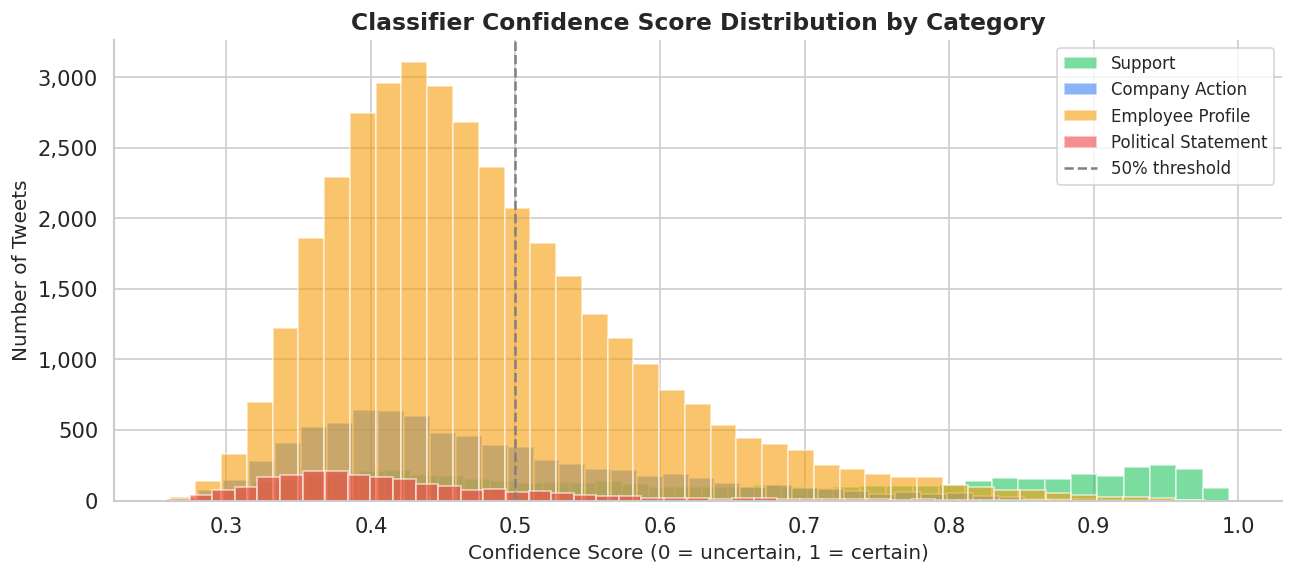

CONFIDENCE SCORES BY CATEGORY


,Mean Confidence,Median Confidence,Min Confidence
category,,,
Company Action,0.475,0.445,0.262
Employee Profile,0.479,0.458,0.261
Political Statement,0.427,0.401,0.259
Support,0.648,0.638,0.264


In [20]:
# ── Confidence distribution by category ──────────────────────────────────────
fig, ax = plt.subplots(figsize=(11, 5))

for cat in cat_order:
    subset = df_lgbtq[df_lgbtq['category'] == cat]['confidence'].dropna()
    ax.hist(subset, bins=40, alpha=0.6, label=cat,
            color=CAT_COLORS[cat], edgecolor='white')

ax.axvline(0.5, color='gray', linestyle='--', linewidth=1.5, label='50% threshold')
ax.set_title('Classifier Confidence Score Distribution by Category')
ax.set_xlabel('Confidence Score (0 = uncertain, 1 = certain)')
ax.set_ylabel('Number of Tweets')
ax.legend(fontsize=10)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
sns.despine()
plt.tight_layout()
plt.savefig('fig_confidence_dist.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Summary stats ─────────────────────────────────────────────────────────────
conf_stats = df_lgbtq.groupby('category')['confidence'].agg(['mean','median','min']).round(3)
conf_stats.columns = ['Mean Confidence', 'Median Confidence', 'Min Confidence']
print('CONFIDENCE SCORES BY CATEGORY')
display(conf_stats.style.format('{:.3f}').background_gradient(cmap='Greens'))

---
## Section 9 — Example Tweets per Category

Reviewing examples confirms the classifier is working correctly

In [21]:
# ── Top 5 highest-confidence examples per category ───────────────────────────
for cat in cat_order:
    subset = (
        df_lgbtq[df_lgbtq['category'] == cat]
        .nlargest(5, 'confidence')
        [['author_userName', 'text', 'confidence']]
        .reset_index(drop=True)
    )
    print(f'\n{"═"*65}')
    print(f'  {cat.upper()}  (top 5 by confidence)')
    print(f'{"═"*65}')
    for _, row in subset.iterrows():
        print(f'  [{row["author_userName"]}]  confidence={row["confidence"]:.3f}')
        print(f'  "{row["text"][:160]}"')
        print()

---
## Section 10 — Low Confidence Review

Tweets where the classifier was unsure (confidence < 0.40) are worth a quick manual review to spot any systematic errors.

In [22]:
LOW_CONF_THRESHOLD = 0.40

low_conf = df_lgbtq[df_lgbtq['confidence'] < LOW_CONF_THRESHOLD].copy()

print(f'Tweets below {LOW_CONF_THRESHOLD} confidence: {len(low_conf):,}  '
      f'({len(low_conf)/len(df_lgbtq)*100:.1f}% of total)')

print('\nLow-confidence category breakdown:')
display(low_conf['category'].value_counts().to_frame())

print('\nSample low-confidence tweets:')
sample_low = low_conf.sample(min(10, len(low_conf)), random_state=42)
for _, row in sample_low.iterrows():
    print(f'  [{row["author_userName"]}]  assigned={row["category"]}  conf={row["confidence"]:.3f}')
    print(f'  "{row["text"][:150]}"')
    print()

Tweets below 0.4 confidence: 13,235  (25.1% of total)

Low-confidence category breakdown:


,count
category,
Employee Profile,8734
Company Action,2453
Political Statement,1159
Support,889


---
## Section 11 — Summary

Auto-generated findings table based on the classification results.

In [23]:
total_classified = df_lgbtq['category'].notna().sum()
dominant_cat     = df_lgbtq['category'].value_counts().idxmax()
dominant_pct     = df_lgbtq['category'].value_counts().max() / total_classified * 100
political_pct    = (df_lgbtq['category'] == 'Political Statement').sum() / total_classified * 100
mean_conf        = df_lgbtq['confidence'].mean()
low_conf_pct     = (df_lgbtq['confidence'] < LOW_CONF_THRESHOLD).mean() * 100

findings = pd.DataFrame([
    {'Metric': 'Total LGBTQ+ tweets classified',
     'Result': f'{total_classified:,}'},
    {'Metric': 'Dominant category',
     'Result': f'{dominant_cat}  ({dominant_pct:.1f}%)'},
    {'Metric': 'Political Statement share',
     'Result': f'{political_pct:.1f}%'},
    {'Metric': 'Mean classifier confidence',
     'Result': f'{mean_conf:.3f}'},
    {'Metric': f'Tweets below {LOW_CONF_THRESHOLD} confidence (uncertain)',
     'Result': f'{low_conf_pct:.1f}%'},
    {'Metric': 'Output file',
     'Result': 'lgbtq_tweets_classified.csv'},
])

print('CLASSIFICATION SUMMARY')
display(findings.style.hide(axis='index').set_properties(**{'text-align': 'left'}))

CLASSIFICATION SUMMARY


Metric,Result
Total LGBTQ+ tweets classified,"52,791"
Dominant category,Employee Profile (70.1%)
Political Statement share,4.4%
Mean classifier confidence,0.494
Tweets below 0.4 confidence (uncertain),25.1%
Output file,lgbtq_tweets_classified.csv


## Saved Files

**Figures:**
- `fig_cat_overall_dist.png` — Bar and pie chart of overall category distribution
- `fig_cat_yearly_trend.png` — Category mix by year (stacked bar + line chart)
- `fig_cat_monthly.png` — Category mix by month
- `fig_cat_by_company.png` — Category breakdown for top 20 companies
- `fig_confidence_dist.png` — Classifier confidence distribution

**Data:**
- `lgbtq_tweets_classified.csv` — Full LGBTQ+ tweet dataset with category labels and scores
- `lgbtq_classified_checkpoint.csv` — Checkpoint file (safe to delete after run completes)

---
